In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
style.use('dark_background')

# Importing data

In [ ]:
from google.colab import drive#montar el drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Course Material/Supervised Machine Learning/Regression Analysis #ir a la carpeta

/content/drive/MyDrive/Course Material/Supervised Machine Learning/Regression Analysis


In [ ]:
df = pd.read_csv('Regression_Data.csv')#leer csv carpeta

In [ ]:
df

,Ind_Data,Dependent_Data
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


# Create arrays for features and target variable

In [ ]:
X = df['Ind_Data'].values
X

array([ 1.1,  1.3,  1.5,  2. ,  2.2,  2.9,  3. ,  3.2,  3.2,  3.7,  3.9,
        4. ,  4. ,  4.1,  4.5,  4.9,  5.1,  5.3,  5.9,  6. ,  6.8,  7.1,
        7.9,  8.2,  8.7,  9. ,  9.5,  9.6, 10.3, 10.5])

In [ ]:
y = df['Dependent_Data'].values
y

array([ 39343,  46205,  37731,  43525,  39891,  56642,  60150,  54445,
        64445,  57189,  63218,  55794,  56957,  57081,  61111,  67938,
        66029,  83088,  81363,  93940,  91738,  98273, 101302, 113812,
       109431, 105582, 116969, 112635, 122391, 121872])

# Visualizing the Scatter plot between X and y

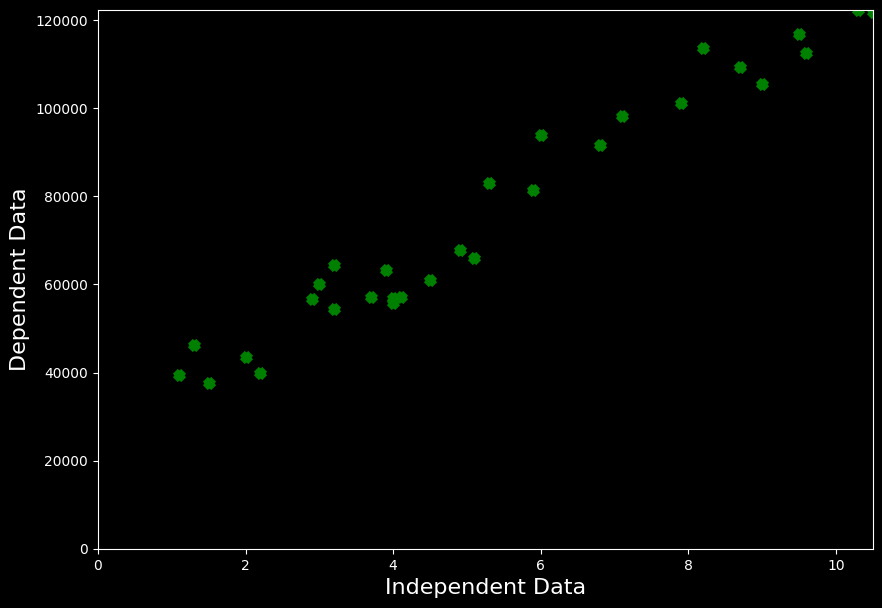

In [ ]:
plt.figure(figsize=(10,7))
plt.scatter(X, y, marker = "x", color = 'g', lw = 5)
plt.xlabel('Independent Data', fontsize = 16)
plt.ylabel('Dependent Data', fontsize = 16)
plt.xlim([0, X.max()])
plt.ylim([0, y.max()])
plt.show()

# Applying Least Square

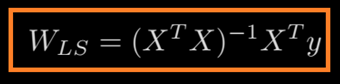

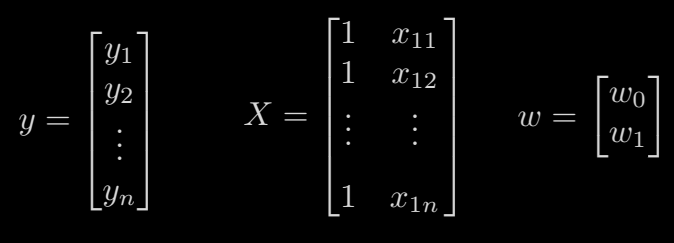

“Least Squares” (Mínimos Cuadrados) es la fórmula matemática clásica para encontrar los parámetros de una Regresión Lineal sin usar gradiente descendente.

Es la solución exacta al problema: ¿Qué recta (o hiperplano) se ajusta mejor a mis datos? Formula: WLS​=(X^t*X)^−1X^t*y


Es la forma cerrada (closed-form) de obtener los pesos w de una regresión lineal.

Por qué se usan cuadrados y no valores absolutos

son derivables, penalizan más los errores grandes, permiten usar álgebra lineal para obtener una solución exacta

Least Squares = método para encontrar la recta que mejor se ajusta minimizando la suma de los errores al cuadrado.
###-> ejemplo simple
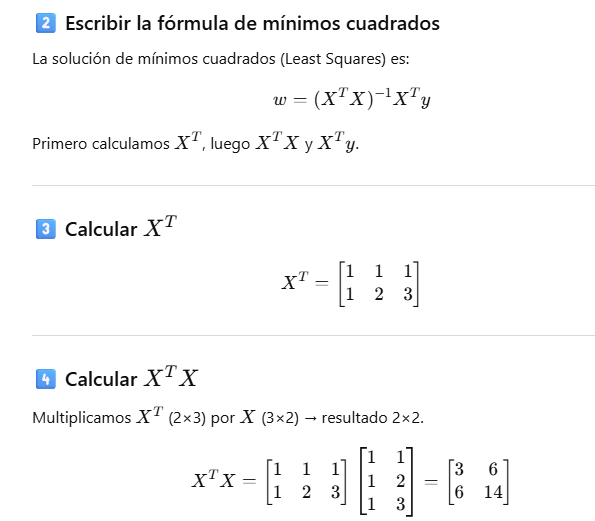

Cómo se obtiene cada elemento:

(1,1): 1⋅1+1⋅1+1⋅1=3


(1,2): 1⋅1+1⋅2+1⋅3=6


(2,1): 1⋅1+2⋅1+3⋅1=6


(2,2): 1⋅1+2⋅2+3⋅3=1+4+9=14

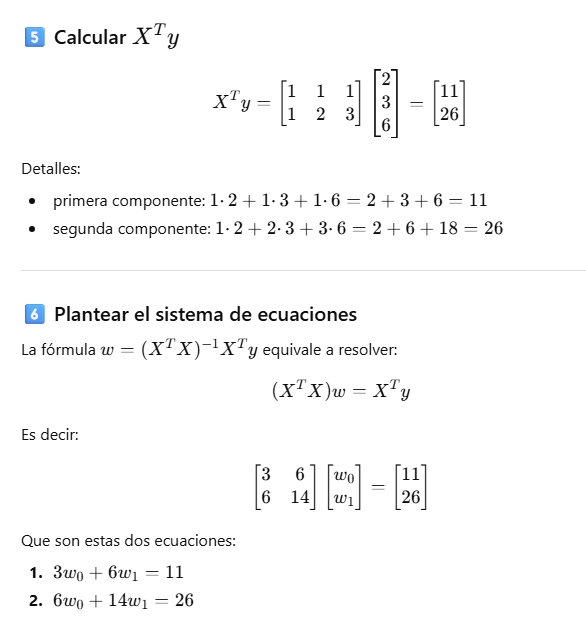



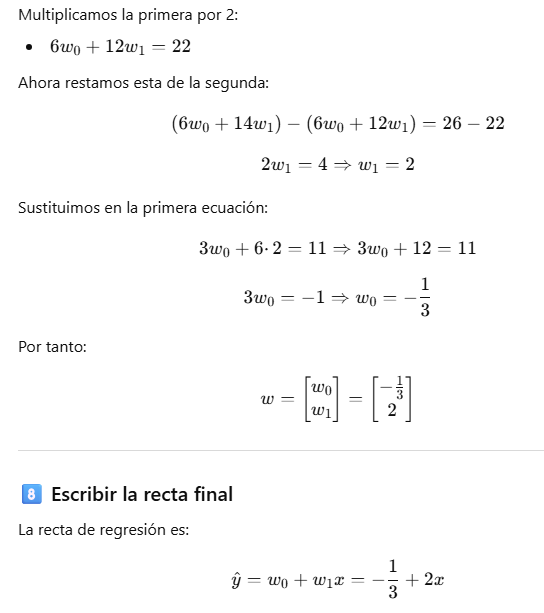

# Appending ones at the first column of X

In [ ]:
ones = np.ones((len(X),1)) # crea una columna de 1’s con tantas filas como elementos tenga X.
ones

#en Machine Learning se usa para construir la matriz X de regresión lineal con intercepto. para aplicar la fórmula de mínimos cuadrados:

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

In [ ]:
X = X.reshape(-1,1)
X

array([[ 1.1],
       [ 1.3],
       [ 1.5],
       [ 2. ],
       [ 2.2],
       [ 2.9],
       [ 3. ],
       [ 3.2],
       [ 3.2],
       [ 3.7],
       [ 3.9],
       [ 4. ],
       [ 4. ],
       [ 4.1],
       [ 4.5],
       [ 4.9],
       [ 5.1],
       [ 5.3],
       [ 5.9],
       [ 6. ],
       [ 6.8],
       [ 7.1],
       [ 7.9],
       [ 8.2],
       [ 8.7],
       [ 9. ],
       [ 9.5],
       [ 9.6],
       [10.3],
       [10.5]])

In [ ]:
Xls = np.concatenate((ones,X),axis=1)

In [ ]:
Xls

array([[ 1. ,  1.1],
       [ 1. ,  1.3],
       [ 1. ,  1.5],
       [ 1. ,  2. ],
       [ 1. ,  2.2],
       [ 1. ,  2.9],
       [ 1. ,  3. ],
       [ 1. ,  3.2],
       [ 1. ,  3.2],
       [ 1. ,  3.7],
       [ 1. ,  3.9],
       [ 1. ,  4. ],
       [ 1. ,  4. ],
       [ 1. ,  4.1],
       [ 1. ,  4.5],
       [ 1. ,  4.9],
       [ 1. ,  5.1],
       [ 1. ,  5.3],
       [ 1. ,  5.9],
       [ 1. ,  6. ],
       [ 1. ,  6.8],
       [ 1. ,  7.1],
       [ 1. ,  7.9],
       [ 1. ,  8.2],
       [ 1. ,  8.7],
       [ 1. ,  9. ],
       [ 1. ,  9.5],
       [ 1. ,  9.6],
       [ 1. , 10.3],
       [ 1. , 10.5]])

In [ ]:
y = y.reshape(-1,1)
y

array([[ 39343],
       [ 46205],
       [ 37731],
       [ 43525],
       [ 39891],
       [ 56642],
       [ 60150],
       [ 54445],
       [ 64445],
       [ 57189],
       [ 63218],
       [ 55794],
       [ 56957],
       [ 57081],
       [ 61111],
       [ 67938],
       [ 66029],
       [ 83088],
       [ 81363],
       [ 93940],
       [ 91738],
       [ 98273],
       [101302],
       [113812],
       [109431],
       [105582],
       [116969],
       [112635],
       [122391],
       [121872]])

# Applying Least Square Method

In [ ]:
XT = np.transpose(Xls)   # Transpose of X #transponer una matriz

In [ ]:
prod_X = np.matmul(XT,Xls)   # Calculating XT * X   #multiplicación matricial traspuesta *xls(1's con independent_data=X)

In [ ]:
Inv_X = np.linalg.inv(prod_X)             # calculating inverse of (XT * X)   # inversa de una matriz

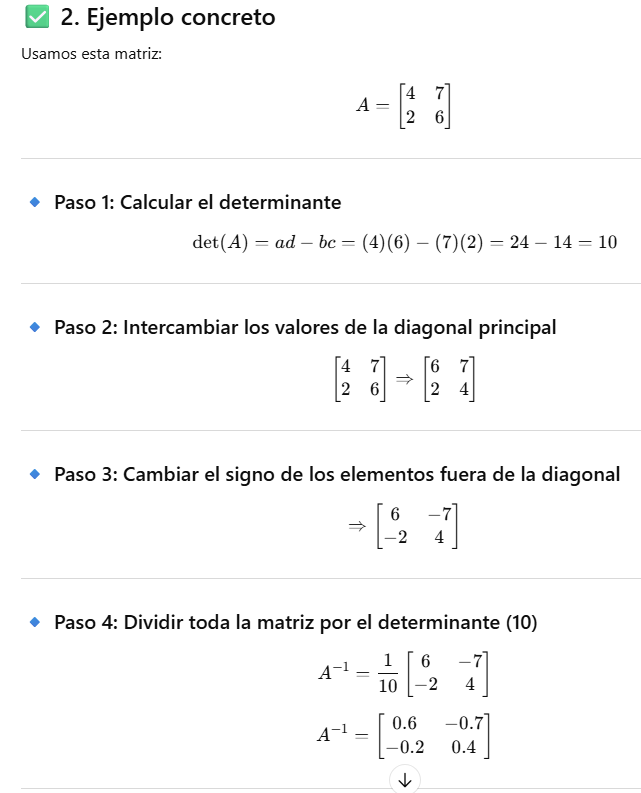

In [ ]:
XTy = np.matmul(XT,y)  # calculating (XT * y) #producto matricial de la traspuesta *y (dependent_data)

In [ ]:
wLS = np.matmul(Inv_X,XTy)#producto matricial inversa*xty

In [ ]:
wLS

array([[25792.20019867],
       [ 9449.96232146]])

In [ ]:
w0 = wLS[0].round(2)
w0

array([25792.2])

In [ ]:
w1 = wLS[1].round(2)
w1

array([9449.96])

# Interpreting the concept of weight

### w1 shows that the value of dependent variable increases by 9449.96 if the value of independent variable increases by one unit.

# Testing the model

In [ ]:
test_data = np.linspace(0,11,30)#Genera 30 valores igualmente espaciados de 0-11

In [ ]:
test_data

array([ 0.        ,  0.37931034,  0.75862069,  1.13793103,  1.51724138,
        1.89655172,  2.27586207,  2.65517241,  3.03448276,  3.4137931 ,
        3.79310345,  4.17241379,  4.55172414,  4.93103448,  5.31034483,
        5.68965517,  6.06896552,  6.44827586,  6.82758621,  7.20689655,
        7.5862069 ,  7.96551724,  8.34482759,  8.72413793,  9.10344828,
        9.48275862,  9.86206897, 10.24137931, 10.62068966, 11.        ])

In [ ]:
test_labels = np.linspace(np.min(y), np.max(y), 30)

In [ ]:
test_labels

array([ 37731.        ,  40650.31034483,  43569.62068966,  46488.93103448,
        49408.24137931,  52327.55172414,  55246.86206897,  58166.17241379,
        61085.48275862,  64004.79310345,  66924.10344828,  69843.4137931 ,
        72762.72413793,  75682.03448276,  78601.34482759,  81520.65517241,
        84439.96551724,  87359.27586207,  90278.5862069 ,  93197.89655172,
        96117.20689655,  99036.51724138, 101955.82758621, 104875.13793103,
       107794.44827586, 110713.75862069, 113633.06896552, 116552.37931034,
       119471.68965517, 122391.        ])

In [ ]:
### Use the equation of regression to calculate predicted Values
y_pred = w0 + w1 * test_data  # y = w0 + w1X

# Visualizing the model performance

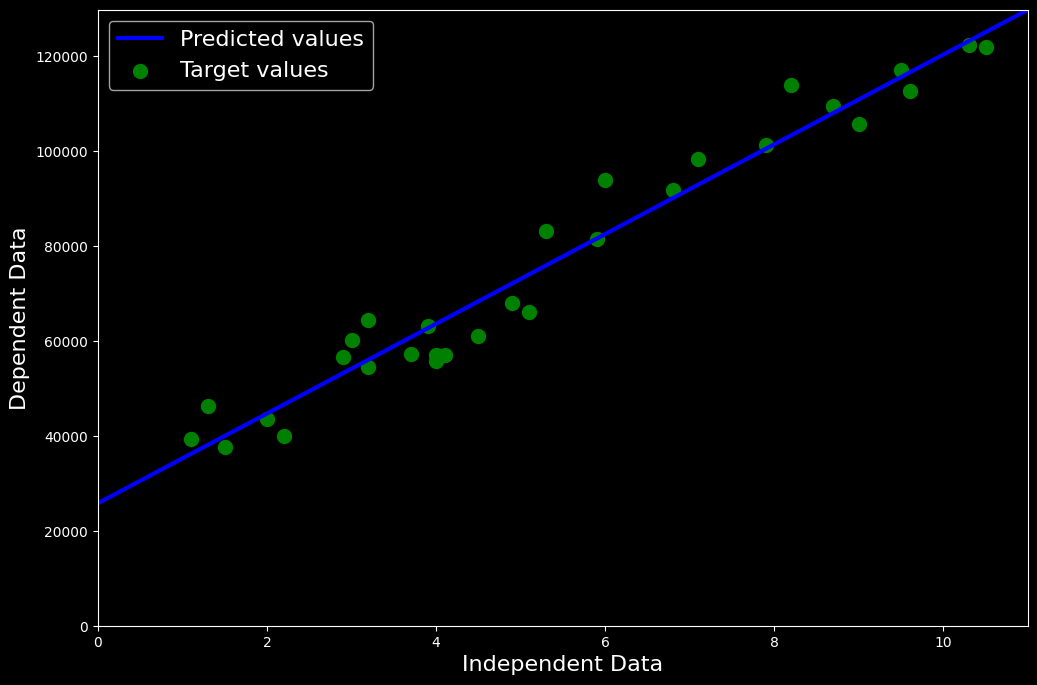

In [ ]:
plt.figure(figsize=(12,8))
plt.xlim([0, test_data.max()])
plt.ylim([0, y_pred.max()])
plt.plot(test_data, y_pred, color='blue', label='Predicted values', linewidth = 3)
plt.scatter(X, y, c='green', label='Target values', linewidth = 5)
plt.xlabel('Independent Data', fontsize = 16)
plt.ylabel('Dependent Data', fontsize = 16)
plt.legend(fontsize = 16)
plt.show()


# Evaluating Regression Performance

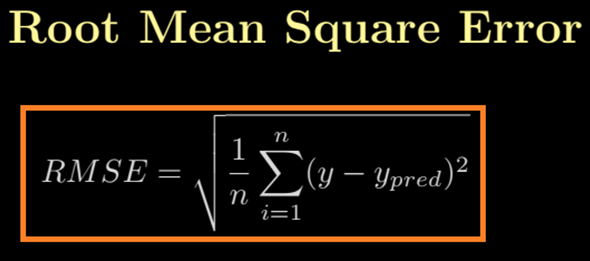

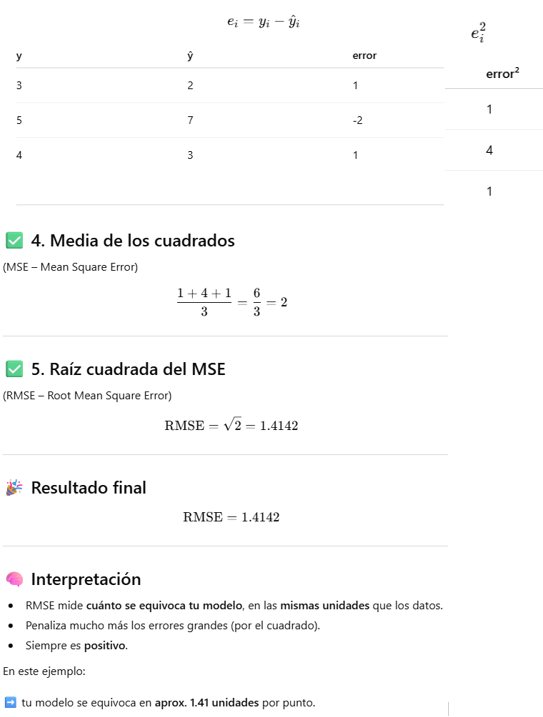

In [ ]:
rmse = 0#variable acumuladora donde iremos sumando los errores cuadrados.
for i in range(len(test_labels)):#El bucle recorre cada punto del dataset de test.
    y_pred = w0 + w1 * test_data[i]# Cálculo de la predicción con la fórmula de la recta de regresión: y^​=w0​+w1​x
    rmse += (test_labels[i] - y_pred) ** 2 #El error cuadrado por cada punto es:(yi​−y^​i​)2. Los vas sumando todos.
rmse = np.sqrt(rmse/len(test_labels))# Esto aplica la fórmula completa: de raiz de error cuadratico medio
print('RMSE : ',rmse)

RMSE :  [6197.43656114]


In [ ]:
test_labels

array([ 37731.        ,  40650.31034483,  43569.62068966,  46488.93103448,
        49408.24137931,  52327.55172414,  55246.86206897,  58166.17241379,
        61085.48275862,  64004.79310345,  66924.10344828,  69843.4137931 ,
        72762.72413793,  75682.03448276,  78601.34482759,  81520.65517241,
        84439.96551724,  87359.27586207,  90278.5862069 ,  93197.89655172,
        96117.20689655,  99036.51724138, 101955.82758621, 104875.13793103,
       107794.44827586, 110713.75862069, 113633.06896552, 116552.37931034,
       119471.68965517, 122391.        ])

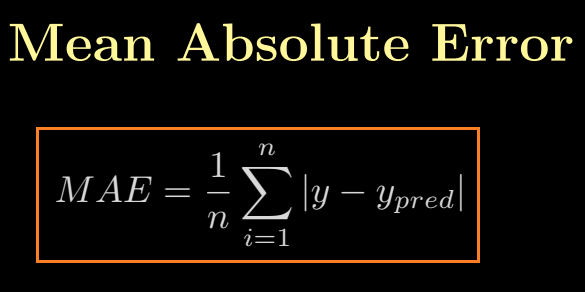

In [ ]:
mae = 0
for i in range(len(test_labels)): # Recorre cada índice i de los datos de prueba de len(test_labels) indica cuántos ejemplos hay.
    y_pred = w0 + w1 * test_data[i] # Calcula la predicción del modelo para ese dato:
    # wo= intercepto/bias/El bias es el valor donde la recta corta al eje Y (cuando x = 0).
    # w1= pendiente/peso, test_data[i]-> valor de entrada x
    mae += abs(test_labels[i] - y_pred)# calcula valor absoulto y hace un sumatorio
mae = mae / len(test_labels) # media de los errores absolutos sumados
print('MAE :', mae)

MAE : [5247.93613793]


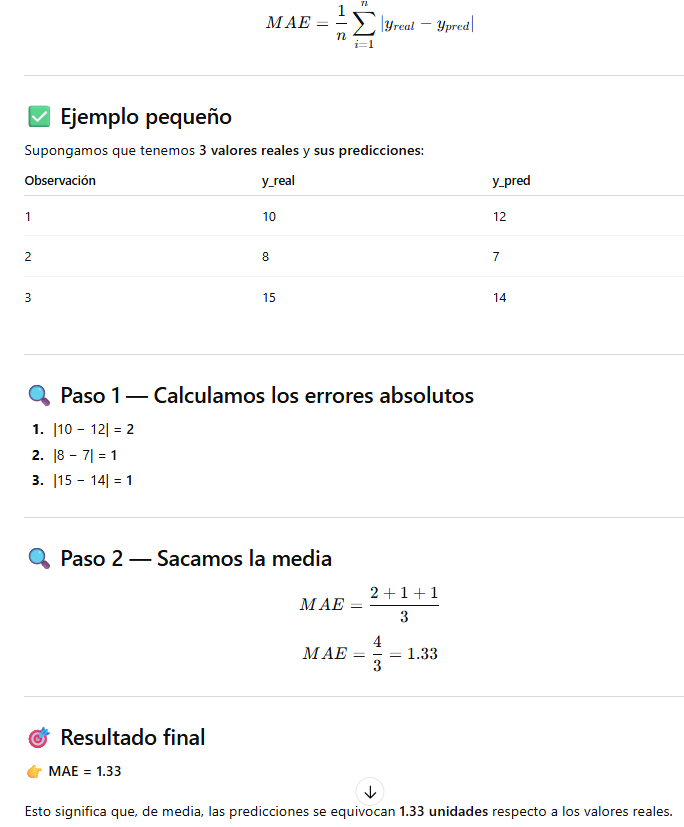

In [ ]:
#coeficiente de determinación

#R² mide qué porcentaje de la variabilidad de los datos reales explica el modelo.

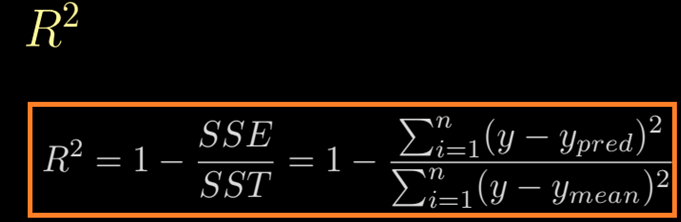

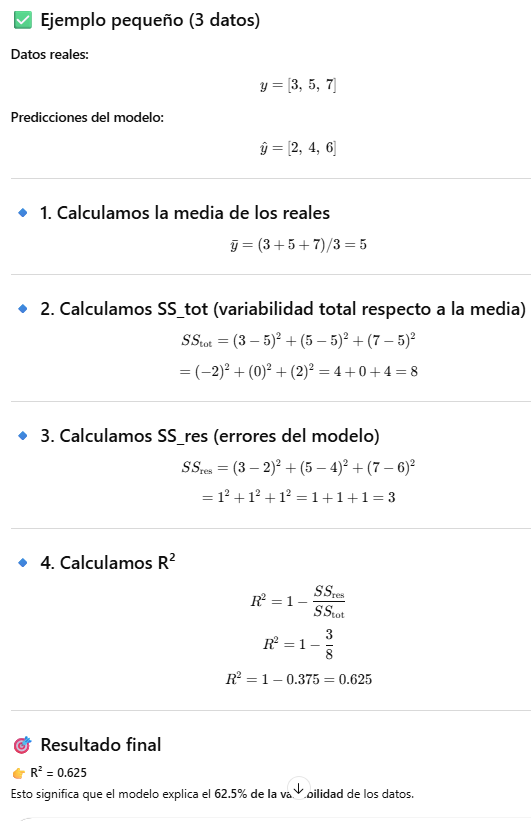

In [ ]:
SSE = 0 #inicializa Sum of Squared Errors
SST = 0 # Total Sum of Squares
for i in range(len(test_labels)):  #Recorre cada ejemplo del conjunto de prueba.
    y_pred = w0 + w1 * test_data[i]  #Calcula la predicción del modelo usando la recta:
    SSE += (test_labels[i] - y_pred) ** 2  # Calcula el error cuadrático del modelo
    SST += (test_labels[i] - np.mean(y)) ** 2 # Calcula la variabilidad total de los datos reales respecto a la media
R2 = 1 - (SSE/SST) # Aplica la fórmula del coeficiente de determinación
print('R2 :',R2)


R2 : [0.94135569]


#  Using sklearn to perform Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()  # instantiate Linear Regression

In [ ]:
lr.fit(X,y)  # Sk-Learn also does least square fitting  # Entrena el modelo de regresión lineal usando los datos: x,y
print("Intercept:", lr.intercept_)
# Muestra el intercepto (w0) del modelo. Es el valor donde la recta corta el eje Y: el bias del modelo ypred=w0​cuando X=0
print("Coefficient:", lr.coef_)
#Muestra el coeficiente (w1), es decir, la pendiente de la recta: w1 = como cambia ypred cuando x aumenta 1ud

Intercept: [25792.20019867]
Coefficient: [[9449.96232146]]


In [ ]:
test_data = test_data.reshape(-1,1)#datos de entrenamiento del modelo

In [ ]:
y_pred = lr.predict(test_data)
#usa el modelo de regresión lineal ya entrenado (lr) para hacer predicciones sobre nuevos datos.

#llama a la forma ypred= wo+w1*x

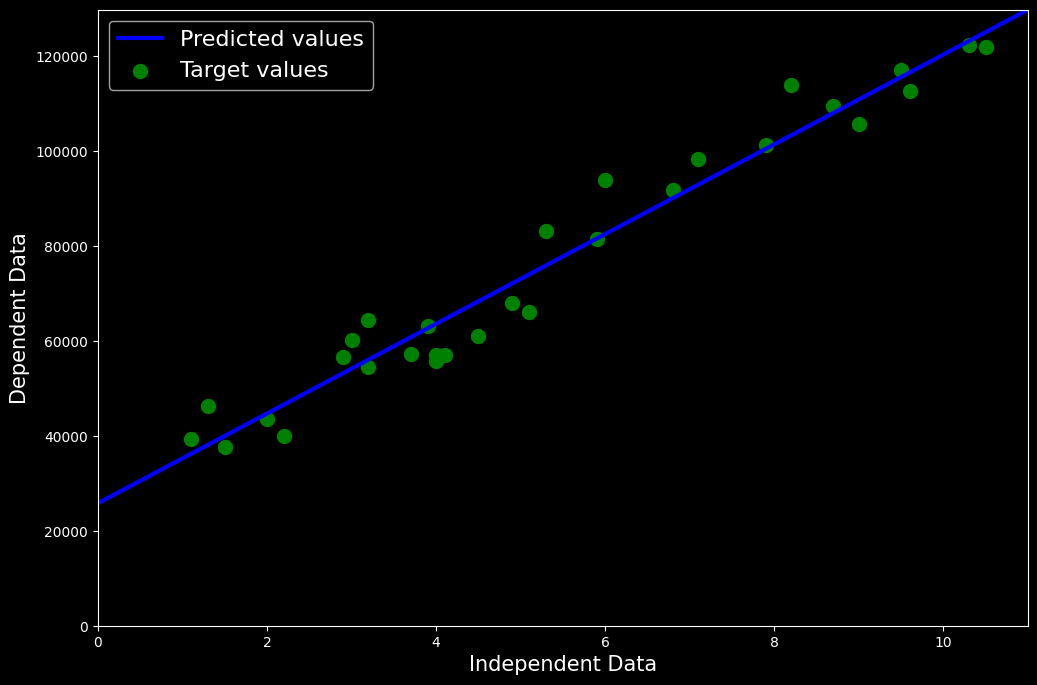

In [ ]:
plt.figure(figsize=(12,8))
plt.xlim([0, test_data.max()])
plt.ylim([0, y_pred.max()])
plt.plot(test_data, y_pred, color='blue', label='Predicted values', linewidth = 3)
plt.scatter(X, y, c='green', label='Target values', linewidth = 5)
plt.xlabel('Independent Data', fontsize = 15)
plt.ylabel('Dependent Data', fontsize = 15)
plt.legend(fontsize = 16)
plt.show()


In [ ]:
from sklearn import metrics # Importa el módulo metrics de Scikit-Learn, que contiene funciones para evaluar modelos

#Una métrica es una forma de medir/evaluar/cuantificar el rendimiento de un modelo.
print('RMSE:', np.sqrt(metrics.mean_squared_error(test_labels, y_pred)))
 # calcula MSE. Penaliza más fuerte los errores grandes, frecuente en regresión
print('MAE:', metrics.mean_absolute_error(test_labels, y_pred))
# calcula el MAE, es más robusto frente a outliers (datos que sobresalen)
# mide cuanto se equivoca el modelo de media en valor absoluto
print('R2:', metrics.r2_score(test_labels, y_pred))

#calcula coeficiente determinación r2. SSE errores modelo, SST variacion total datos reales
#mide que porcentaje de la variabilidad explica el modelo


RMSE: 6197.438841666302
MAE: 5247.939884570575
R2: 0.9398430898737059
